In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


In [21]:
data = {
    'Name' : ['Pavan', 'kapil', 'Lalit', 'ishan', 'om'],
    'Age' : [25, None, 44, 23, None],
    'Salary' : [50000, 60000, 70000, None, None]
}

df = pd.DataFrame(data)
print("Original dataframe")
print(df)


Original dataframe
    Name   Age   Salary
0  Pavan  25.0  50000.0
1  kapil   NaN  60000.0
2  Lalit  44.0  70000.0
3  ishan  23.0      NaN
4     om   NaN      NaN


In [22]:
print(df.isnull().sum())  # it show the missing values in each column

print(df.isnull().mean() * 100)

Name      0
Age       2
Salary    2
dtype: int64
Name       0.0
Age       40.0
Salary    40.0
dtype: float64


In [9]:
df_drop = df.dropna()  # it removes the rown with missing values
print(df_drop)

    Name   Age   Salary
0  Pavan  25.0  50000.0
2  Lalit  44.0  70000.0


In [19]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

df['Salary'] = df['Salary'].fillna(df['Salary'].mean())

print(df)


    Name        Age   Salary
0  Pavan  25.000000  50000.0
1  kapil  30.666667  60000.0
2  Lalit  44.000000  70000.0
3  ishan  23.000000  60000.0
4     om  30.666667  60000.0


In [ ]:
pip install scikit-learn

In [31]:

# Label encoding  = changing text with unique numbers

from sklearn.preprocessing import LabelEncoder
import pandas as pd

df = pd.read_csv("student_data.csv")

df_label = df.copy()

le = LabelEncoder()

df_label['Gender_Encoded'] = le.fit_transform(df_label['gender']) # fit transfrom conver the male female into 0 or 1 for learning
df_label['Passed_Encoded'] = le.fit_transform(df_label['passed'])

print('\nLabel encoded data')
print(df_label[['name','gender','Gender_Encoded','passed','Passed_Encoded']])


Label encoded data
           name  gender  Gender_Encoded passed  Passed_Encoded
0  Aarav Sharma  Female               0     No               0
1   Priya Patel  Female               0    Yes               1
2   Rohan Gupta  Female               0     No               0
3  Ananya Singh  Female               0     No               0
4  Vikram Kumar    Male               1    Yes               1
5    Neha Verma    Male               1     No               0
6    Amit Joshi    Male               1     No               0
7   Pooja Reddy  Female               0     No               0
8    Rahul Nair  Female               0    Yes               1
9     Sneha Das  Female               0     No               0


In [34]:
df_encoded = pd.get_dummies(df, columns = ['city'], dtype = int)
print('\nOne-Hot encoded data (city)')
print(df_encoded)


One-Hot encoded data (city)
           name  gender passed  city_Ahmedabad  city_Bangalore  city_Chennai  \
0  Aarav Sharma  Female     No               0               1             0   
1   Priya Patel  Female    Yes               0               1             0   
2   Rohan Gupta  Female     No               0               0             0   
3  Ananya Singh  Female     No               0               0             1   
4  Vikram Kumar    Male    Yes               1               0             0   
5    Neha Verma    Male     No               0               0             0   
6    Amit Joshi    Male     No               0               0             0   
7   Pooja Reddy  Female     No               0               0             0   
8    Rahul Nair  Female    Yes               0               0             0   
9     Sneha Das  Female     No               0               0             0   

   city_Kolkata  city_Mumbai  city_Pune  
0             0            0          0  
1     

In [35]:
# Feature scaling

In [39]:
#standred scaling

from sklearn.preprocessing import StandardScaler
import pandas as pd

data = {
    'StudyHours' : [1, 2, 3, 4, 5],
    'TestScore' : [40, 50, 60, 70, 80]
}


df = pd.DataFrame(data)

# standardscaler

standard_scaler = StandardScaler()
standard_scaled = standard_scaler.fit_transform(df)

print("Standard Scalaer Output:")
print(pd.DataFrame(standard_scaled, columns = ['StudyHours','TestScore']))

Standard Scalaer Output:
   StudyHours  TestScore
0   -1.414214  -1.414214
1   -0.707107  -0.707107
2    0.000000   0.000000
3    0.707107   0.707107
4    1.414214   1.414214


In [40]:
# minmax Scaler

from sklearn.preprocessing import MinMaxScaler
import pandas as pd

data = {
    'StudyHours' : [1, 2, 3, 4, 5],
    'TestScore' : [40, 50, 60, 70, 80]
}


df = pd.DataFrame(data)

# MinMaxScaler

minmax_scaler = MinMaxScaler()
minmax_scaled = minmax_scaler.fit_transform(df)

print("MinMax Scaler Output:")
print(pd.DataFrame(minmax_scaled, columns = ['StudyHours','TestScore']))

MinMax Scaler Output:
   StudyHours  TestScore
0        0.00       0.00
1        0.25       0.25
2        0.50       0.50
3        0.75       0.75
4        1.00       1.00


In [49]:
# Train and test data

from sklearn.model_selection import train_test_split

x = df[['StudyHours']]
y = df[['TestScore']]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Training Data")
print(x_train)
print("Testing data")
print(x_test)

print("Training Data - Y")
print(y_train)
print("Testing data - Y")
print(y_test)

Training Data
   StudyHours
4           5
2           3
0           1
3           4
Testing data
   StudyHours
1           2
Training Data - Y
   TestScore
4         80
2         60
0         40
3         70
Testing data - Y
   TestScore
1         50


# supervised machine learning

In [60]:
#linear regression

from sklearn.linear_model import LinearRegression

x = [[1], [2], [3], [4], [5]]
y = [40, 50, 65, 75, 90]

model = LinearRegression()

model.fit(x, y)

hours = float(input("Enter hours:"))

predicted_marks = model.predict([[hours]])

print(f"based on your {hours} hours, you may score around {predicted_marks} marks")

Enter hours: 10


based on your 10.0 hours, you may score around [151.5] marks


In [67]:


from sklearn.linear_model import LogisticRegression

x = [[1],[2],[3],[4],[5]]
y = [0,0,0,1,1]

model = LogisticRegression()

model.fit(x,y)

hours = float(input("How many hours you studied :"))

result = model.predict([[hours]])[0]
if result == 1:
    print(f"based you your studied hours:{hours}, you are passed")
else:
    print(f"based you your studied hours:{hours}, you are failed")


How many hours you studied : 11


based you your studied hours:11.0, you are passed


In [74]:


from sklearn.neighbors import KNeighborsClassifier

x = [[180, 7],
     [200, 7.5],
     [250, 8],
     [300, 8.5]
     ,[330, 9]
     ,[360, 9.5]
    ]


# 0 - apple, 1 = orange
y = [0,0,0,1,1,1]

model = KNeighborsClassifier(n_neighbors = 3)

model.fit(x,y)

weight = float(input("Enter the weight : "))
size = float(input("Enter the size in cm :"))

result = model.predict([[weight, size]])[0]  #<-- this o is to get clean anser as 1,0 without this it will give ans in list fromat [0],[1]

if result == 0:
    print("this is an apple")
else:
    print("this is an orange")





Enter the weight :  233
Enter the size in cm : 4


this is an apple


In [79]:


from sklearn.tree import DecisionTreeClassifier

x = [[7, 2],
     [8, 3],
     [9, 8],
     [10, 9]
    ]

y = [0,0,1,1]


model = DecisionTreeClassifier()

model.fit(x,y)

size = float(input("Enter the size:"))
shade = float(input("enter the shade:"))

result = model.predict([[size, shade]])[0]

if result == 0 :
    print("This is an apple")
else:
    print("This is an orange")

Enter the size: 8.5
enter the shade: 4


This is an apple


In [ ]:
#  Topic                	  What it does	                                               Priority

# StandardScaler	        Standardizes features using the mean and standard deviation	   High
# MinMaxScaler	        Scales features to a specified range, usually 0 to 1	           High
# train_test_split	    Splits data into training and testing sets	                       Must learn
# LinearRegression	    Predicts continuous numerical values, such as salary	           Must learn
# LogisticRegression	    Predicts classes, such as pass/fail	                           Must learn
# KNeighborsClassifier	Classifies data using nearby examples	                           High
# DecisionTreeClassifier	Classifies data using decision rules	                       High

In [87]:

# Classification Matrics


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# true answer
y_true = [1, 0, 1, 1, 0, 1, 0]

# model prediction
y_pred = [1, 0, 1, 0, 0, 1, 1]

print("Accuracy :", accuracy_score(y_true,y_pred))
print("Precision :", precision_score(y_true,y_pred))
print("Recall :", recall_score(y_true,y_pred))
print("F1 :", f1_score(y_true,y_pred))




Accuracy : 0.7142857142857143
Precision : 0.75
Recall : 0.75
F1 : 0.75


In [96]:

# confusion matrix

from sklearn.metrics import confusion_matrix

y_true = [1,0,1,1,0,1,0,0,1,0]
y_pred = [1,0,1,0,0,1,1,0,1,0]

model =  confusion_matrix(y_true, y_pred)

print("Confusion matix\n")
print(model)



Confusion matix

[[4 1]
 [1 4]]


In [104]:
"""
MAE - MEAN ABSOLUTE ERROR

1- take the mistake difference
2- remove the minus sign
3- add
4- devide
7.5 on an avarage

2. MSE MEAN SQUARED ERROR

1- mistake square them
2- add
3- devite total

RMSE - ROOT MEAN SQUARED ERROR

"""

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

actual_score = [90, 60, 80, 100]

predected_score = [85, 70, 70, 95]

mae = mean_absolute_error(actual_score,predected_score)
mse = mean_squared_error(actual_score,predected_score)
rmse = np.sqrt(mse)

print("MAE: predicion off by :", mae)
print("MSE: squared mistake value :", mse)
print("MAE: final realistic error:", rmse)

MAE: predicion off by : 7.5
MSE: squared mistake value : 62.5
MAE: final realistic error: 7.905694150420948


In [106]:
"""
Data preprocessing
- LabelEncoder — converts categorical labels into numeric labels.
- StandardScaler — standardizes numerical features.
- MinMaxScaler — scales features to a specified range.



Data splitting
- train_test_split — separates data into training and testing sets.



Machine Learning algorithms
- LinearRegression — predicts continuous numerical values.
- LogisticRegression — predicts classes.
- KNeighborsClassifier — classifies using nearby examples.
- DecisionTreeClassifier — classifies using decision rules.



Model evaluation
- accuracy_score — overall correctness.
- precision_score — correctness of positive predictions.
- recall_score — proportion of actual positives identified.
- f1_score — balance between precision and recall.
- confusion_matrix — counts correct and incorrect classifications.
- mean_absolute_error — average absolute prediction error.
- mean_squared_error — average squared prediction error.

"""

'\nData preprocessing\n- LabelEncoder — converts categorical labels into numeric labels.\n- StandardScaler — standardizes numerical features.\n- MinMaxScaler — scales features to a specified range.\n\n\n\nData splitting\n- train_test_split — separates data into training and testing sets.\n\n\n\nMachine Learning algorithms\n- LinearRegression — predicts continuous numerical values.\n- LogisticRegression — predicts classes.\n- KNeighborsClassifier — classifies using nearby examples.\n- DecisionTreeClassifier — classifies using decision rules.\n\n\n\nModel evaluation\n- accuracy_score — overall correctness.\n- precision_score — correctness of positive predictions.\n- recall_score — proportion of actual positives identified.\n- f1_score — balance between precision and recall.\n- confusion_matrix — counts correct and incorrect classifications.\n- mean_absolute_error — average absolute prediction error.\n- mean_squared_error — average squared prediction error.\n\n'

# unsupervised learning

In [107]:
# k means - elbow method

import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [109]:
data = {
    'Customers ' : ['Priya', 'Akshay', 'neha', 'Sushant', 'Sneha', 'Banti'],
    'Age' : [20, 30, 40, 22, 38, 25],
    'Spending' : [100, 200, 300, 110, 290, 130]
}

df = pd.DataFrame(data)
print(df)

  Customers   Age  Spending
0      Priya   20       100
1     Akshay   30       200
2       neha   40       300
3    Sushant   22       110
4      Sneha   38       290
5      Banti   25       130


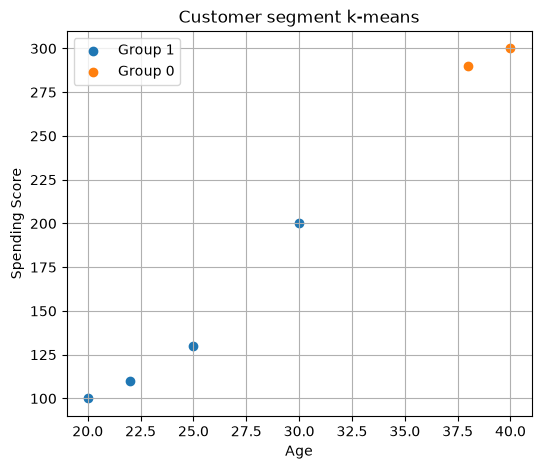

  Customers   Age  Spending  Group
0      Priya   20       100      1
1     Akshay   30       200      1
2       neha   40       300      0
3    Sushant   22       110      1
4      Sneha   38       290      0
5      Banti   25       130      1


In [114]:
X = df[['Age', 'Spending']]

model = KMeans(n_clusters=2, random_state=42, n_init=10)

df['Group'] = model.fit_predict(X) 
#df['Group']  add new column name group in data

plt.figure(figsize=(6, 5)) # graph size

for group in df['Group'].unique():
    group_data = df[df['Group'] == group]
    plt.scatter(group_data['Age'], group_data['Spending'], label=f'Group {group}')

plt.xlabel('Age')
plt.ylabel('Spending Score')
plt.title('Customer segment k-means')
plt.legend()
plt.grid(True)
plt.show()

print(df)

Variance captured by each pca componant :
[99.65  0.35]


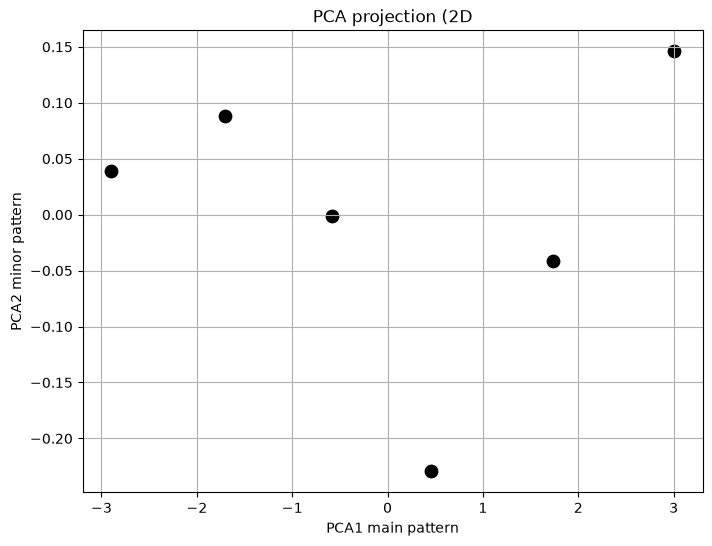

New data with 2 features PCA1 AND PCA2
       PCA1      PCA2
0 -2.901838  0.038962
1 -1.703939  0.088054
2 -0.585677 -0.001447
3  0.452949 -0.229542
4  1.730485 -0.041856
5  3.008020  0.145829


In [122]:
# pca - Principle Componant analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = {

    'Age' : [25, 30, 35, 40, 45, 50],
    'Income' : [30000, 40000, 50000, 60000, 70000, 80000],
    'Spending' :[70, 60, 50, 40, 30, 20],
    'Savings' : [1000, 5000, 8000, 10000, 15000, 20000]
}

df = pd.DataFrame(data)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

pca = PCA(n_components = 2)
pca_result = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(pca_result, columns=['PCA1', 'PCA2'])

explained_variance = pca.explained_variance_ratio_

print("Variance captured by each pca componant :")
print(np.round(explained_variance * 100, 2))


plt.figure(figsize=(8,6))
plt.scatter(pca_df['PCA1'], pca_df['PCA2'], color='black', s = 80)
plt.title("PCA projection (2D")
plt.xlabel("PCA1 main pattern")
plt.ylabel("PCA2 minor pattern")
plt.grid(True)
plt.show()

print("New data with 2 features PCA1 AND PCA2")
print(pca_df)

In [123]:
# Variance captured by each component
print("Explained variance ratio:")
print(np.round(pca.explained_variance_ratio_ * 100, 2))

# Total variance retained
print("Total variance retained:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Contribution of each original feature
loadings = pd.DataFrame(
    pca.components_.T,
    index=df.columns,
    columns=['PCA1', 'PCA2']
)

print("\nPCA Component Loadings:")
print(loadings.round(3))

Explained variance ratio:
[99.65  0.35]
Total variance retained:
100.0 %

PCA Component Loadings:
           PCA1   PCA2
Age       0.501 -0.288
Income    0.501 -0.288
Spending -0.501  0.288
Savings   0.498  0.867


----------------------------All Data----------------- 
    StudyHours  Attendance  PastScore Internet  SleepHours Passed
0            2          60         40      Yes           5     No
1            5          80         60       No           6    Yes
2            8          90         75      Yes           8    Yes
3            3          70         50      Yes           5     No
4            7          85         70       No           7    Yes
5            1          50         30       No           4     No
6            6          78         68      Yes           6    Yes
7            4          65         55       No           5     No
8            9          95         80      Yes           9    Yes
9            2          55         35       No           4     No
10           5          76         65      Yes           6    Yes
11           6          88         72      Yes           7    Yes
12           1          40         25       No           3     No
13           3       

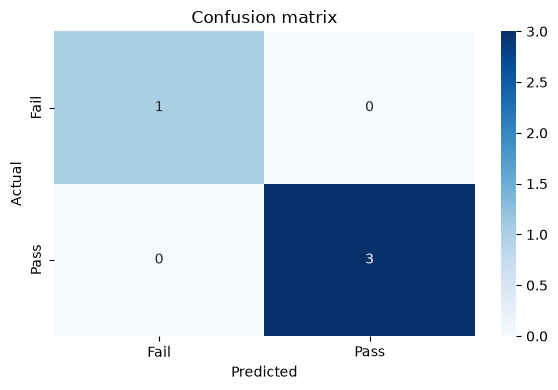

-----Pridict your result---------


Enter your Study hours: 5
Enter your attendance: 40
Enter your past score: 50
Enter your sleep hours: 8


Prediction based on your input : Fail


C:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
